# Judge comparison: answer leakage across judge families and sizes

**Study:** Implication-Weighted Data Selection for Financial QA, and the AAAI workshop paper (`specs/Protocol_for_AAAI_workshop.md`, Experiment 6, RQ3).
**Runs analysed:** `python -m fqsel judges`, 25–26 October 2026. Four open-weight LLM judges answered the Jev battery on the 995 original/negative pairs used for Spec 3's A1.

This notebook documents:

- the four judges, how they were served, and the quality of their measurements;
- **RQ1 for every judge:** does R separate verified gold answers from constructed wrong answers?
- **RQ2/RQ3:** does a determinacy question that sees the stated answer leak correctness (battery v0)? Does rewording (v1) or hiding the answer (v2) remove it? And does this depend on the judge's family and size?
- the separability of R and I under each battery, the consequence question Q3, paraphrase robustness, and agreement between judges;
- Jev on the same 995 pairs as the reference judge.

**Purely descriptive.** It reads only frozen snapshots, each verified against its `SHA256SUMS`:

- `code/runs/judges_2026-10-26/` (final per-judge tables and manifests);
- `code/runs/judges_core_2026-10-25/` (the core-run copies, to confirm the paraphrase runs left the core answers unchanged);
- `code/runs/full_v2_2026-10-25/` (the pool and Jev under battery v2, primary);
- `code/runs/full_v0_2026-10-24/` (Jev under battery v0, pre-registered).

It imports nothing from the pipeline, calls no API, and changes no code, configuration or output. Its only outputs are this notebook and `notebooks/figures/judges_*.pdf`.

## 0. Where this fits

The battery analysis (notebook 02) found that Jev's determinacy question Q2, when it can see the stated answer (battery v0), separates wrong answers almost as well as the support question Q1. Rewording it to "assume the stated answer is correct" (v1) reduced that only a little; asking it without the stated answer (v2) removed it by construction. What remained was a moderate correlation between Q1 and Q2 at the level of items.

That finding rests on one closed, decision-only judge. The judge comparison asks whether it is a property of LLM judges in general, and whether it changes with the judge's size and family:

| Judge | Family | Size | Served by | Precision | Questions |
| --- | --- | --- | --- | --- | --- |
| Llama 3.2 3B Instruct | Llama | 3B | Parasail | bf16 | core |
| Llama 3.3 70B Instruct | Llama | 70B | Parasail | fp8 | core |
| Gemma 3 4B | Gemma | 4B | Parasail | bf16 | core + paraphrases |
| Gemma 4 31B (reasoning off) | Gemma | 31B | Parasail | fp8 | core + paraphrases |
| Jev (`jev-1.14.0`) | — | — | TypeSafe | — | full battery, v0 and v2 runs |

**Design, identical for every judge.** One question per request, verbatim from the frozen battery files: Q1 and Q3 on the item with its stated answer; Q2 in its v0 and v1 wordings on the same state, and in its v2 wording on the state without the stated answer. P(yes) is read from the first answer token's log-probabilities (temperature 0, one token, top-20 log-probabilities, yes/no variants summed and renormalised).

**Status in the protocol.** Exploratory: not one of Protocol v1's pre-registered hypotheses, and no gate reads it. **Known confounds:** within each family the larger judge is also served in fp8 (the planned bf16 endpoint for Gemma 4 31B was rate-limited, and Llama 3.3 70B was moved to the same provider by the owner); the Gemma pair spans two generations; Llama 3.3 70B and Gemma 4 31B differ in size. Comparisons therefore use rank-based measures only (AUROC, Spearman), never P(yes) levels.

## 1. Setup and integrity of the snapshots

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import roc_auc_score

CODE = Path.cwd().parent / "code"
RUNS = CODE / "runs"
SNAPSHOTS = ["judges_2026-10-26", "judges_core_2026-10-25", "full_v2_2026-10-25", "full_v0_2026-10-24"]
FIG_DIR = Path.cwd() / "figures"
FIG_DIR.mkdir(exist_ok=True)
N_BOOT = 2000
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

JUDGES = ["llama32_3b", "llama33_70b", "gemma3_4b", "gemma4_31b", "jev"]
LABEL = {"llama32_3b": "Llama 3.2 3B", "llama33_70b": "Llama 3.3 70B", "gemma3_4b": "Gemma 3 4B",
         "gemma4_31b": "Gemma 4 31B", "jev": "Jev"}
FAMILY = {"llama32_3b": "Llama", "llama33_70b": "Llama", "gemma3_4b": "Gemma", "gemma4_31b": "Gemma", "jev": "Jev"}
SIZE_B = {"llama32_3b": 3, "llama33_70b": 70, "gemma3_4b": 4, "gemma4_31b": 31}
PAIRS_BY_FAMILY = {"Llama": ("llama32_3b", "llama33_70b"), "Gemma": ("gemma3_4b", "gemma4_31b")}
COLORS = {"llama32_3b": "#9ecae1", "llama33_70b": "#2166ac", "gemma3_4b": "#fdae6b", "gemma4_31b": "#d94801",
          "jev": "#4d4d4d"}
VCOL = {"v0": "#9a9a9a", "v1": "#d1603d", "v2": "#3b6ea5"}


def verify(folder: Path) -> bool:
    for line in (folder / "SHA256SUMS").read_text().splitlines():
        digest, rel = line.split(maxsplit=1)
        if hashlib.sha256((folder / rel).read_bytes()).hexdigest() != digest:
            return False
    return True

for s in SNAPSHOTS:
    print(f"{s:24s} checksums verified: {verify(RUNS / s)}")

judges_2026-10-26        checksums verified: True
judges_core_2026-10-25   checksums verified: True
full_v2_2026-10-25       checksums verified: True
full_v0_2026-10-24       checksums verified: True


**Loading.** Every judge's wide table holds, per item: R = P(yes | Q1), Q2 under v0, v1 and v2, Q3, and I\_v = mean(Q2\_v, Q3). Jev's scores come from its two full-pool runs, restricted to the same 1,990 items: battery v2 supplies R, Q2\_v2, Q3 and I\_v2; battery v0 supplies Q2\_v0, I\_v0 and its own Q1 (`R_v0`), so that each battery's correlations use the Q1 scored alongside it, as in notebook 02. Jev was never scored with v1 on the full pool (v1 was rejected on the 200-item pilot), so its v1 cells are empty.

In [2]:
pool = pd.read_parquet(RUNS / "full_v2_2026-10-25" / "data" / "pool.parquet")
meta = pool.set_index("item_id")[["dataset", "answer_type", "is_derived", "base_item_id", "perturbation"]]

wide, long, manifest = {}, {}, {}
for j in JUDGES[:-1]:
    d = RUNS / "judges_2026-10-26" / j
    wide[j] = pd.read_parquet(d / f"{j}.parquet").set_index("item_id")
    long[j] = pd.read_parquet(d / f"{j}_long.parquet")
    manifest[j] = json.loads((d / f"{j}_manifest.json").read_text())

items = wide["gemma3_4b"].index
assert all(wide[j].index.equals(items) for j in JUDGES[:-1]), "judges must cover the same items"


def jev_frame(run):
    root = RUNS / run / "scores"
    lg = pd.read_parquet(root / "jev_scores_long.parquet")
    q = lg.assign(k=lg["battery"] + "_" + lg["question"]).pivot(index="item_id", columns="k", values="p_yes")
    return q.join(pd.read_parquet(root / "jev_scores.parquet").set_index("item_id")[["I", "I_para"]])

j2, j0 = jev_frame("full_v2_2026-10-25"), jev_frame("full_v0_2026-10-24")
wide["jev"] = pd.DataFrame({
    "R": j2["orig_q1"], "R_v0": j0["orig_q1"], "Q2_v0": j0["orig_q2"], "Q2_v1": np.nan, "Q2_v2": j2["orig_q2"],
    "Q3": j2["orig_q3"], "I_v0": j0["I"], "I_v1": np.nan, "I_v2": j2["I"],
    "R_para": j2["para_q1"], "Q2_v0_para": j0["para_q2"], "Q2_v2_para": j2["para_q2"], "Q3_para": j2["para_q3"],
}).loc[items]
assert wide["jev"][["R", "Q2_v0", "Q2_v2", "Q3"]].notna().all().all()

info = meta.loc[items]
orig_ids = info.index[~info["is_derived"]]
pairs = info[info["is_derived"]][["base_item_id"]].rename_axis("neg_id").reset_index()
assert pairs["base_item_id"].isin(orig_ids).all() and pairs["base_item_id"].is_unique
pos_ids, neg_ids = pairs["base_item_id"].to_numpy(), pairs["neg_id"].to_numpy()
print(f"items {len(items):,}: originals {len(orig_ids):,}, negatives {len(neg_ids):,}, pairs {len(pairs):,}")
print("pairs by dataset:", info.loc[pos_ids, "dataset"].value_counts().to_dict(),
      "| by answer type:", info.loc[pos_ids, "answer_type"].value_counts().to_dict())

items 1,990: originals 995, negatives 995, pairs 995
pairs by dataset: {'tatqa': 676, 'finqa': 319} | by answer type: {'arith': 609, 'lookup': 386}


In [3]:
# The paraphrase runs must have left every original-battery answer unchanged (Gemma pair).
for j in ("gemma3_4b", "gemma4_31b"):
    core = pd.read_parquet(RUNS / "judges_core_2026-10-25" / j / f"{j}_long.parquet")
    final = long[j][long[j]["battery"] == "orig"]
    cols = ["item_id", "question", "variant", "p_yes"]
    same = core[cols].sort_values(cols[:3]).reset_index(drop=True).equals(final[cols].sort_values(cols[:3]).reset_index(drop=True))
    print(f"{LABEL[j]:13s} original-battery answers identical to the core run: {same}")

# paraphrase columns in the same layout as Jev's
for j in ("gemma3_4b", "gemma4_31b"):
    p = long[j][long[j]["battery"] == "para"].assign(k=lambda d: d["question"] + "_" + d["variant"]) \
        .pivot(index="item_id", columns="k", values="p_yes")
    wide[j] = wide[j].join(p.rename(columns={"q1_all": "R_para", "q3_all": "Q3_para", "q2_v0": "Q2_v0_para",
                                             "q2_v1": "Q2_v1_para", "q2_v2": "Q2_v2_para"}))

Gemma 3 4B    original-battery answers identical to the core run: True
Gemma 4 31B   original-battery answers identical to the core run: True


## 2. Provenance and measurement quality

In [4]:
rows = []
for j in JUDGES[:-1]:
    m, lg = manifest[j], long[j]
    first = lg["top_token"].str.strip().str.lower()
    rows.append({"judge": LABEL[j], "endpoint": m["model_version"].split("@")[1], "served model": ", ".join(m["served_models"]),
                 "paraphrases": m["include_paraphrase"], "rows": len(lg), "requests": m["n_distinct_requests"],
                 "P(yes) missing %": 100 * m["share_p_yes_null"],
                 "yes/no mass, min": lg["mass"].min(), "yes/no mass, p1": lg["mass"].quantile(0.01),
                 "first token not yes/no %": 100 * (~first.isin(["yes", "no"])).mean(),
                 "share 'yes' %": 100 * (first == "yes").mean(),
                 "repeat |ΔP| mean": m["determinism"]["mean_abs_diff"], "repeat |ΔP| max": m["determinism"]["max_abs_diff"],
                 "repeats compared": m["determinism"]["n_compared"],
                 "input tokens (M)": m["input_tokens"] / 1e6, "cost $": m["cost_usd"]})
quality = pd.DataFrame(rows).set_index("judge")
jev_det = json.loads((RUNS / "full_v2_2026-10-25" / "results" / "jev_manifest.json").read_text())["determinism"]["mean_abs_diff"]
display(quality)
print(f"Jev (full v2 run), repeat |ΔP| mean: {jev_det:.4f}; probabilities rounded to 0.01 by the API")
print(f"total cost of the four judges: ${quality['cost $'].sum():.2f}")

,endpoint,served model,paraphrases,rows,requests,P(yes) missing %,"yes/no mass, min","yes/no mass, p1",first token not yes/no %,share 'yes' %,repeat |ΔP| mean,repeat |ΔP| max,repeats compared,input tokens (M),cost $
judge,,,,,,,,,,,,,,,
Llama 3.2 3B,parasail/bf16,meta-llama/llama-3.2-3b-instruct,False,9950,8955,0.0,0.984,0.999,0.000,31.307,0.007,0.061,987,6.182,0.312
Llama 3.3 70B,parasail/fp8,meta-llama/llama-3.3-70b-instruct,False,9950,8955,0.0,0.234,0.993,0.101,64.241,0.019,0.808,987,6.182,0.808
Gemma 3 4B,parasail/bf16,google/gemma-3-4b-it,True,19900,17910,0.0,1.000,1.000,0.000,89.467,0.003,0.440,1974,13.610,0.352
Gemma 4 31B,parasail/fp8,google/gemma-4-31b-it,True,19900,17910,0.0,1.000,1.000,0.000,67.477,0.013,0.991,1974,13.681,1.289


Jev (full v2 run), repeat |ΔP| mean: 0.0121; probabilities rounded to 0.01 by the API
total cost of the four judges: $2.76


## 3. RQ1: does R separate verified gold answers from constructed wrong answers?

Each pair is an original (label 1) and its negative copy with a wrong stated answer (label 0). AUROCs come with a **pair-clustered bootstrap** (2,000 resamples of pairs), as in notebooks 01–02. The same resampled pair indices are used for every judge and every score, so that differences between judges or scores can be bootstrapped jointly.

In [5]:
rng = np.random.default_rng(20261026)
BOOT = rng.integers(0, len(pairs), size=(N_BOOT, len(pairs)))   # shared resamples of pair indices


def scores(j, col):
    s = wide[j][col]
    return s.loc[pos_ids].to_numpy(), s.loc[neg_ids].to_numpy()


def auc_idx(pos, neg, idx):
    return roc_auc_score(np.r_[np.ones(len(idx)), np.zeros(len(idx))], np.r_[pos[idx], neg[idx]])


def auc_boot(j, col, mask=None):
    """Point AUROC and its bootstrap replicates over pairs (optionally within a subset of pairs)."""
    pos, neg = scores(j, col)
    if np.isnan(pos).all():
        return np.nan, np.full(N_BOOT, np.nan)
    base = np.arange(len(pairs)) if mask is None else np.flatnonzero(mask)
    point = auc_idx(pos, neg, base)
    if mask is None:
        reps = np.array([auc_idx(pos, neg, b) for b in BOOT])
    else:
        r2 = np.random.default_rng(1)
        reps = np.array([auc_idx(pos, neg, r2.choice(base, len(base))) for _ in range(N_BOOT)])
    return point, reps


def ci(point, reps):
    if np.isnan(point):
        return "—"
    lo, hi = np.percentile(reps, [2.5, 97.5])
    return f"{point:.3f} [{lo:.3f}, {hi:.3f}]"

AUC = {(j, c): auc_boot(j, c) for j in JUDGES for c in ("R", "Q2_v0", "Q2_v1", "Q2_v2", "Q3", "I_v0", "I_v1", "I_v2")}
display(pd.DataFrame({LABEL[j]: {"AUROC of R": ci(*AUC[(j, "R")])} for j in JUDGES}).T)

,AUROC of R
Llama 3.2 3B,"0.689 [0.670, 0.705]"
Llama 3.3 70B,"0.880 [0.866, 0.894]"
Gemma 3 4B,"0.706 [0.689, 0.723]"
Gemma 4 31B,"0.894 [0.882, 0.908]"
Jev,"0.942 [0.932, 0.952]"


In [6]:
pair_info = info.loc[pos_ids].reset_index(drop=True)
neg_pert = info.loc[neg_ids, "perturbation"].str.replace(r":.*", "", regex=True).where(
    ~info.loc[neg_ids, "perturbation"].str.startswith("factor"), info.loc[neg_ids, "perturbation"]).to_numpy()

subsets = {"FinQA": pair_info["dataset"].eq("finqa").to_numpy(), "TAT-QA": pair_info["dataset"].eq("tatqa").to_numpy(),
           "arith": pair_info["answer_type"].eq("arith").to_numpy(), "lookup": pair_info["answer_type"].eq("lookup").to_numpy()}
sub = pd.DataFrame({LABEL[j]: {f"{k} (n={m.sum()})": ci(*auc_boot(j, "R", m)) for k, m in subsets.items()} for j in JUDGES}).T
display(sub)

pert_order = ["factor:0.5", "factor:2", "factor:1.25", "factor:0.8", "sign_flip", "span_swap"]
pert = pd.DataFrame({LABEL[j]: {f"{p} (n={(neg_pert == p).sum()})": auc_idx(*scores(j, "R"), np.flatnonzero(neg_pert == p))
                                for p in pert_order} for j in JUDGES}).T
print("AUROC of R by perturbation of the wrong answer (point estimates; bool_flip and table_value have < 10 pairs):")
display(pert)

,FinQA (n=319),TAT-QA (n=676),arith (n=609),lookup (n=386)
Llama 3.2 3B,"0.536 [0.515, 0.556]","0.751 [0.729, 0.773]","0.515 [0.502, 0.529]","0.882 [0.862, 0.902]"
Llama 3.3 70B,"0.764 [0.734, 0.794]","0.925 [0.911, 0.938]","0.785 [0.764, 0.807]","0.972 [0.962, 0.982]"
Gemma 3 4B,"0.551 [0.533, 0.571]","0.778 [0.757, 0.797]","0.546 [0.531, 0.560]","0.908 [0.891, 0.927]"
Gemma 4 31B,"0.788 [0.759, 0.817]","0.932 [0.918, 0.945]","0.798 [0.777, 0.819]","0.984 [0.976, 0.992]"
Jev,"0.890 [0.864, 0.916]","0.964 [0.955, 0.973]","0.903 [0.886, 0.921]","0.989 [0.984, 0.994]"


AUROC of R by perturbation of the wrong answer (point estimates; bool_flip and table_value have < 10 pairs):


,factor:0.5 (n=145),factor:2 (n=160),factor:1.25 (n=148),factor:0.8 (n=131),sign_flip (n=181),span_swap (n=218)
Llama 3.2 3B,0.631,0.716,0.653,0.740,0.495,0.831
Llama 3.3 70B,0.874,0.892,0.819,0.879,0.828,0.955
Gemma 3 4B,0.603,0.750,0.695,0.709,0.552,0.904
Gemma 4 31B,0.909,0.924,0.785,0.830,0.848,0.973
Jev,0.970,0.982,0.956,0.953,0.860,0.981


**Findings (RQ1).**
- **Every judge's support question carries correctness information, and more so the larger the judge.** The AUROC of R is 0.69 (Llama 3.2 3B) and 0.71 (Gemma 3 4B) for the small judges, 0.88 (Llama 3.3 70B) and 0.89 (Gemma 4 31B) for the large ones, and 0.94 for Jev. Intervals do not overlap between the small and the large judges.
- **The small judges barely check arithmetic.** On arithmetic items their AUROC is 0.52–0.55, close to chance, and on sign flips 0.50–0.55; nearly all their signal comes from lookup items (0.88–0.91), where a swapped span is easy to spot. The large judges reach 0.79–0.80 on arithmetic and Jev 0.90.
- **The hardest wrong answers are the same for every judge:** sign flips and the subtle ×1.25 factor. Span swaps are the easiest. This matches Jev's pattern in notebooks 01–02.
- **For the paper:** R's validity is not a Jev-specific property, but its strength is. A 3–4B judge is not a usable reliability gate for computed answers.

## 4. RQ2/RQ3: answer leakage in the determinacy question

**Leakage measure.** Q2's AUROC on the pairs: how well the determinacy question separates the verified answer from a wrong one. Under v2 the original and its negative share one answer-free request, so the AUROC is exactly 0.5 by construction; under v0 and v1 any separation above 0.5 is correctness information leaking into determinacy.

**Leakage index.** Judges differ in how well they detect wrong answers at all, so the raw AUROC is also shown relative to the judge's own support question: **L = (AUROC of Q2 − 0.5) / (AUROC of R − 0.5)**, the share of the judge's correctness signal that its determinacy question reproduces. L = 0 means no leakage; L = 1 means Q2 is as good a correctness detector as Q1. Intervals come from the shared pair bootstrap.

In [7]:
def leak_index(j, v):
    q, qr = AUC[(j, f"Q2_{v}")]
    r, rr = AUC[(j, "R")]
    return (q - 0.5) / (r - 0.5), (qr - 0.5) / (rr - 0.5)

rows = {}
for j in JUDGES:
    row = {f"AUROC Q2 {v}": ci(*AUC[(j, f"Q2_{v}")]) for v in ("v0", "v1", "v2")}
    row |= {f"L {v}": ci(*leak_index(j, v)) for v in ("v0", "v1")}
    pe0, pe1 = AUC[(j, "Q2_v0")], AUC[(j, "Q2_v1")]
    row["Δ AUROC v0 − v1"] = ci(pe0[0] - pe1[0], pe0[1] - pe1[1])
    rows[LABEL[j]] = row
leak = pd.DataFrame(rows).T
display(leak)
same_v2 = {LABEL[j]: bool(np.array_equal(*scores(j, "Q2_v2"))) for j in JUDGES}
print("Q2 (v2) identical for every original and its negative:", same_v2)

,AUROC Q2 v0,AUROC Q2 v1,AUROC Q2 v2,L v0,L v1,Δ AUROC v0 − v1
Llama 3.2 3B,"0.614 [0.600, 0.629]","0.583 [0.569, 0.597]","0.500 [0.500, 0.500]","0.606 [0.561, 0.651]","0.439 [0.387, 0.490]","0.032 [0.022, 0.042]"
Llama 3.3 70B,"0.859 [0.845, 0.873]","0.841 [0.826, 0.856]","0.500 [0.500, 0.500]","0.943 [0.928, 0.959]","0.898 [0.877, 0.919]","0.017 [0.012, 0.024]"
Gemma 3 4B,"0.659 [0.643, 0.675]","0.675 [0.659, 0.692]","0.500 [0.500, 0.500]","0.773 [0.732, 0.812]","0.849 [0.808, 0.889]","-0.016 [-0.024, -0.007]"
Gemma 4 31B,"0.890 [0.877, 0.902]","0.834 [0.819, 0.849]","0.500 [0.500, 0.500]","0.988 [0.974, 1.002]","0.848 [0.821, 0.872]","0.055 [0.048, 0.063]"
Jev,"0.922 [0.911, 0.933]",—,"0.500 [0.500, 0.500]","0.955 [0.943, 0.968]",—,—


Q2 (v2) identical for every original and its negative: {'Llama 3.2 3B': True, 'Llama 3.3 70B': True, 'Gemma 3 4B': True, 'Gemma 4 31B': True, 'Jev': True}


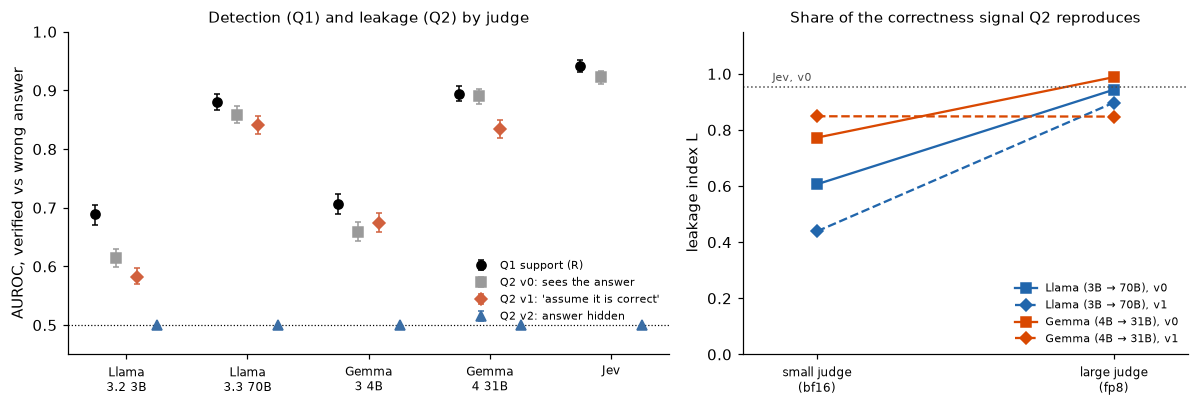

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
x = np.arange(len(JUDGES))
for k, (col, lab, mk) in enumerate([("R", "Q1 support (R)", "o"), ("Q2_v0", "Q2 v0: sees the answer", "s"),
                                     ("Q2_v1", "Q2 v1: 'assume it is correct'", "D"), ("Q2_v2", "Q2 v2: answer hidden", "^")]):
    pts = [AUC[(j, col)] for j in JUDGES]
    y = np.array([p[0] for p in pts])
    err = np.array([[p[0] - np.percentile(p[1], 2.5), np.percentile(p[1], 97.5) - p[0]] if not np.isnan(p[0]) else [0, 0] for p in pts]).T
    ax.errorbar(x + (k - 1.5) * 0.17, y, yerr=err, fmt=mk, ms=6, capsize=2, lw=1,
                color={"R": "black", "Q2_v0": VCOL["v0"], "Q2_v1": VCOL["v1"], "Q2_v2": VCOL["v2"]}[col], label=lab)
ax.axhline(0.5, ls=":", color="black", lw=0.8)
ax.set_xticks(x, [LABEL[j].replace(" ", "\n", 1) for j in JUDGES], fontsize=8)
ax.set_ylabel("AUROC, verified vs wrong answer")
ax.set_ylim(0.45, 1.0)
ax.set_title("Detection (Q1) and leakage (Q2) by judge", fontsize=10)
ax.legend(frameon=False, fontsize=7, loc="lower right", bbox_to_anchor=(1.0, 0.07), ncol=1)

ax = axes[1]
for fam, (small, large) in PAIRS_BY_FAMILY.items():
    for v, mk in (("v0", "s"), ("v1", "D")):
        pts = [leak_index(j, v) for j in (small, large)]
        ax.plot([0, 1], [p[0] for p in pts], marker=mk, color=COLORS[large],
                ls="-" if v == "v0" else "--", label=f"{fam} ({SIZE_B[small]}B → {SIZE_B[large]}B), {v}")
jv = leak_index("jev", "v0")[0]
ax.axhline(jv, color=COLORS["jev"], ls=":", lw=1)
ax.text(-0.15, jv + 0.02, "Jev, v0", fontsize=7, color=COLORS["jev"])
ax.set_xlim(-0.25, 1.25)
ax.set_xticks([0, 1], ["small judge\n(bf16)", "large judge\n(fp8)"], fontsize=8)
ax.set_ylabel("leakage index L")
ax.set_ylim(0, 1.15)
ax.set_title("Share of the correctness signal Q2 reproduces", fontsize=10)
ax.legend(frameon=False, fontsize=7, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "judges_leakage.pdf", bbox_inches="tight")
plt.show()

**Size contrasts within each family.** The same pairs are scored by both judges of a family, so the difference between the large and the small judge is bootstrapped over pairs jointly. Size here also means fp8 instead of bf16 (and, for Gemma, a newer generation).

In [9]:
rows = {}
for fam, (small, large) in PAIRS_BY_FAMILY.items():
    for name, f in [("AUROC of R", lambda j: AUC[(j, "R")]), ("AUROC of Q2 v0", lambda j: AUC[(j, "Q2_v0")]),
                    ("AUROC of Q2 v1", lambda j: AUC[(j, "Q2_v1")]), ("L v0", lambda j: leak_index(j, "v0")),
                    ("L v1", lambda j: leak_index(j, "v1"))]:
        a, b = f(large), f(small)
        rows[(fam, name)] = {"small": f"{b[0]:.3f}", "large": f"{a[0]:.3f}", "large − small": ci(a[0] - b[0], a[1] - b[1])}
display(pd.DataFrame(rows).T)

small  large           large − small
Llama AUROC of R      0.689  0.880    0.191 [0.176, 0.208]
      AUROC of Q2 v0  0.614  0.859    0.244 [0.229, 0.260]
      AUROC of Q2 v1  0.583  0.841    0.258 [0.243, 0.274]
      L v0            0.606  0.943    0.337 [0.292, 0.383]
      L v1            0.439  0.898    0.459 [0.405, 0.513]
Gemma AUROC of R      0.706  0.894    0.188 [0.173, 0.205]
      AUROC of Q2 v0  0.659  0.890    0.231 [0.215, 0.245]
      AUROC of Q2 v1  0.675  0.834    0.160 [0.142, 0.176]
      L v0            0.773  0.988    0.216 [0.174, 0.257]
      L v1            0.849  0.848  -0.001 [-0.050, 0.044]

**Findings (RQ2/RQ3): answer leakage is general, and it grows with the judge.**
- **Every judge leaks under v0.** When the determinacy question can see the stated answer, it separates wrong answers with AUROC 0.61–0.92 for every judge, far above 0.5.
- **Relative to each judge's own correctness signal, the large judges leak almost completely.** The leakage index L under v0 is 0.61 (Llama 3B) and 0.77 (Gemma 4B), against 0.94 (Llama 70B), 0.99 (Gemma 31B) and 0.96 (Jev): for the large judges and Jev, "is this answer uniquely determined?" is almost as good a correctness detector as "is this answer supported?". Within each family the increase with size is clear (Llama +0.34 [0.29, 0.38], Gemma +0.22 [0.17, 0.26]), with the caveat that size comes with fp8 and, for Gemma, a newer generation.
- **Rewording (v1) does not fix it for any judge.** Asking the judge to assume the answer is correct lowers Q2's AUROC by only 0.02–0.06 (Llama 3B, Llama 70B, Gemma 31B) and raises it slightly for Gemma 4B (by 0.016). L under v1 stays at 0.85–0.90 for three judges; only the weakest judge, Llama 3B, drops to 0.44.
- **Hiding the answer (v2) removes the leakage for every judge,** by construction: Q2 is identical within every pair, so its AUROC is exactly 0.5.
- **For the paper:** the headline result of notebook 02 generalises across two open-weight families and two sizes. The information state, not the wording, is what separates determinacy from correctness, and the more capable the judge, the more it matters. This contradicts the natural expectation that a stronger judge is a cleaner instrument: a stronger judge spots the wrong answer more readily and lets that knowledge into a question that does not ask about it.

## 5. Separability of R and I (gate D3's quantity) under each battery

On the 995 originals: ρ(Q1, Q2) and ρ(R, I\_v) with I\_v = mean(Q2\_v, Q3), Spearman with Fisher-z intervals, as in notebook 02. For Jev, the v0 correlations use the Q1 scored in the v0 run. Gate D3 fires at |ρ(R, I)| ≥ 0.8; it is decided on Jev's primary battery only, and is shown here for reference.

In [10]:
def rho_ci(x, y):
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    if len(x) < 10:
        return np.nan, np.nan, np.nan
    r = stats.spearmanr(x, y)[0]
    z, se = np.arctanh(r), 1 / np.sqrt(len(x) - 3)
    return r, np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)


def fmt(t):
    return "—" if np.isnan(t[0]) else f"{t[0]:.3f} [{t[1]:.3f}, {t[2]:.3f}]"


def q1_for(j, v):
    return "R_v0" if (j == "jev" and v == "v0") else "R"


def sep_table(ids):
    rows = {}
    for j in JUDGES:
        o = wide[j].loc[ids]
        row = {}
        for v in ("v0", "v1", "v2"):
            row[f"ρ(Q1, Q2) {v}"] = fmt(rho_ci(o[q1_for(j, v)].to_numpy(), o[f"Q2_{v}"].to_numpy()))
        for v in ("v0", "v1", "v2"):
            row[f"ρ(R, I) {v}"] = fmt(rho_ci(o[q1_for(j, v)].to_numpy(), o[f"I_{v}"].to_numpy()))
        rows[LABEL[j]] = row
    return pd.DataFrame(rows).T

SEP = sep_table(orig_ids)
display(SEP)
for ds, name in (("finqa", "FinQA"), ("tatqa", "TAT-QA")):
    ids = orig_ids[info.loc[orig_ids, "dataset"].eq(ds).to_numpy()]
    print(f"{name} originals (n={len(ids)}):")
    display(sep_table(ids)[["ρ(R, I) v0", "ρ(R, I) v2"]])

,"ρ(Q1, Q2) v0","ρ(Q1, Q2) v1","ρ(Q1, Q2) v2","ρ(R, I) v0","ρ(R, I) v1","ρ(R, I) v2"
Llama 3.2 3B,"0.697 [0.663, 0.727]","0.521 [0.474, 0.565]","0.468 [0.418, 0.515]","0.502 [0.454, 0.547]","0.332 [0.276, 0.386]","0.383 [0.328, 0.434]"
Llama 3.3 70B,"0.835 [0.815, 0.853]","0.736 [0.706, 0.763]","0.498 [0.450, 0.543]","0.733 [0.703, 0.760]","0.679 [0.644, 0.711]","0.517 [0.470, 0.561]"
Gemma 3 4B,"0.850 [0.832, 0.867]","0.862 [0.846, 0.877]","0.614 [0.574, 0.651]","0.760 [0.732, 0.785]","0.762 [0.735, 0.787]","0.582 [0.539, 0.621]"
Gemma 4 31B,"0.845 [0.826, 0.862]","0.700 [0.667, 0.731]","0.541 [0.495, 0.583]","0.721 [0.690, 0.750]","0.620 [0.581, 0.657]","0.437 [0.385, 0.486]"
Jev,"0.829 [0.809, 0.848]",—,"0.495 [0.446, 0.540]","0.673 [0.637, 0.705]",—,"0.439 [0.387, 0.488]"


FinQA originals (n=319):


,"ρ(R, I) v0","ρ(R, I) v2"
Llama 3.2 3B,"0.576 [0.498, 0.645]","0.423 [0.329, 0.509]"
Llama 3.3 70B,"0.842 [0.807, 0.872]","0.553 [0.472, 0.625]"
Gemma 3 4B,"0.698 [0.637, 0.751]","0.504 [0.418, 0.582]"
Gemma 4 31B,"0.926 [0.908, 0.940]","0.544 [0.461, 0.617]"
Jev,"0.810 [0.768, 0.844]","0.470 [0.379, 0.551]"


TAT-QA originals (n=676):


,"ρ(R, I) v0","ρ(R, I) v2"
Llama 3.2 3B,"0.516 [0.459, 0.569]","0.397 [0.331, 0.458]"
Llama 3.3 70B,"0.634 [0.586, 0.677]","0.394 [0.329, 0.456]"
Gemma 3 4B,"0.696 [0.655, 0.733]","0.444 [0.381, 0.502]"
Gemma 4 31B,"0.583 [0.531, 0.631]","0.341 [0.272, 0.406]"
Jev,"0.562 [0.508, 0.611]","0.357 [0.289, 0.421]"


**Findings: separability of R and I.**
- **Under v2 the coupling falls for every judge.** ρ(Q1, Q2) drops from 0.70–0.85 (v0) to 0.47–0.61 (v2), and ρ(R, I) from 0.50–0.76 to 0.38–0.58.
- **The residual coupling under v2 is similar across judges (0.47–0.61).** Q2 cannot see the answer under v2, so this is covariance between items, as notebook 02 concluded for Jev: questions the context leaves less determinate tend to have gold answers that look less supported. That every judge shows it supports reading it as a property of the items, not of one judge.
- **Gate D3 for reference:** under v0, ρ(R, I) on FinQA reaches 0.84 (Llama 70B), 0.93 (Gemma 31B) and 0.81 (Jev), above D3's 0.8, while every judge is far below it under v2 (FinQA 0.42–0.55). The FinQA coupling that triggered the battery revision for Jev appears in the large open-weight judges too, more strongly.
- **Rewording (v1) again helps unevenly:** it lowers ρ(Q1, Q2) for Llama 3B, Llama 70B and Gemma 31B (0.52–0.74) but not for Gemma 4B (0.86).

## 6. The consequence question Q3, and how I responds to wrong answers

In [11]:
o = {j: wide[j].loc[orig_ids] for j in JUDGES}
q3 = pd.DataFrame({LABEL[j]: {
    "AUROC of Q3 on pairs": ci(*AUC[(j, "Q3")]),
    "ρ(Q1, Q3)": fmt(rho_ci(o[j]["R"].to_numpy(), o[j]["Q3"].to_numpy())),
    "ρ(Q2 v2, Q3)": fmt(rho_ci(o[j]["Q2_v2"].to_numpy(), o[j]["Q3"].to_numpy())),
    "median Q3 (originals)": f"{o[j]['Q3'].median():.3f}",
    "share Q3 ≥ 0.99": f"{(o[j]['Q3'] >= 0.99).mean():.3f}",
    "AUROC of I v0": ci(*AUC[(j, "I_v0")]), "AUROC of I v2": ci(*AUC[(j, "I_v2")]),
} for j in JUDGES}).T
display(q3)

,AUROC of Q3 on pairs,"ρ(Q1, Q3)","ρ(Q2 v2, Q3)",median Q3 (originals),share Q3 ≥ 0.99,AUROC of I v0,AUROC of I v2
Llama 3.2 3B,"0.625 [0.607, 0.643]","0.136 [0.075, 0.197]","0.114 [0.052, 0.175]",0.596,0.001,"0.651 [0.634, 0.667]","0.596 [0.582, 0.610]"
Llama 3.3 70B,"0.798 [0.781, 0.814]","0.425 [0.373, 0.475]","0.249 [0.190, 0.306]",1.000,0.861,"0.864 [0.850, 0.878]","0.730 [0.712, 0.747]"
Gemma 3 4B,"0.657 [0.641, 0.674]","0.431 [0.379, 0.481]","0.428 [0.376, 0.477]",1.000,0.953,"0.684 [0.668, 0.701]","0.628 [0.613, 0.644]"
Gemma 4 31B,"0.716 [0.699, 0.732]","0.048 [-0.014, 0.110]","0.096 [0.034, 0.157]",1.000,0.928,"0.889 [0.876, 0.902]","0.699 [0.683, 0.715]"
Jev,"0.747 [0.730, 0.764]","0.141 [0.080, 0.202]","0.090 [0.028, 0.152]",0.970,0.115,"0.930 [0.920, 0.940]","0.713 [0.696, 0.729]"


**Findings: the consequence question.**
- **Q3 sits at its ceiling for the open-weight judges.** 86–95% of originals get P(yes) ≥ 0.99 from Llama 70B and both Gemma judges (Jev: 12%). Llama 3B is the exception, hovering near 0.6. The ceiling makes Q3 rankings, and I\_Q3-style analyses, unreliable for these judges.
- **Q3 still responds to wrong answers** (AUROC 0.63–0.80), because each negative's check is regenerated from its own wrong answer; this is not leakage in the v0 sense.
- **Q3's relation to Q1 depends on the judge** (ρ 0.05–0.43): Jev and Gemma 31B treat consequence as nearly independent of support, Llama 70B and Gemma 4B do not.
- **I responds to wrong answers far less under v2 than under v0 for every judge** (AUROC of I falls by 0.06–0.22), as the definition of I as implication *given* truth requires.

## 7. Robustness to paraphrase

Paraphrased questions (Q1′, Q2′ in each wording, Q3′) were asked of the Gemma pair; Jev's come from its own runs (Q2′ under v0 and v2). Spearman between each question and its paraphrase, on the 995 originals.

In [12]:
rows = {}
for j in ("gemma3_4b", "gemma4_31b", "jev"):
    w = wide[j].loc[orig_ids]
    row = {"ρ(R, R′)": fmt(rho_ci(w["R"].to_numpy(), w["R_para"].to_numpy()))}
    for v in ("v0", "v1", "v2"):
        c = f"Q2_{v}_para"
        row[f"ρ(Q2, Q2′) {v}"] = fmt(rho_ci(w[f"Q2_{v}"].to_numpy(), w[c].to_numpy())) if c in w else "—"
    row["ρ(Q3, Q3′)"] = fmt(rho_ci(w["Q3"].to_numpy(), w["Q3_para"].to_numpy()))
    pp = scores(j, "R_para")
    row["AUROC of R′"] = f"{auc_idx(*pp, np.arange(len(pairs))):.3f}"
    if "Q2_v0_para" in w:
        row["AUROC of Q2′ v0"] = f"{auc_idx(*scores(j, 'Q2_v0_para'), np.arange(len(pairs))):.3f}"
    rows[LABEL[j]] = row
display(pd.DataFrame(rows).T)

,"ρ(R, R′)","ρ(Q2, Q2′) v0","ρ(Q2, Q2′) v1","ρ(Q2, Q2′) v2","ρ(Q3, Q3′)",AUROC of R′,AUROC of Q2′ v0
Gemma 3 4B,"0.958 [0.952, 0.963]","0.896 [0.883, 0.907]","0.853 [0.835, 0.869]","0.699 [0.666, 0.730]","0.740 [0.710, 0.767]",0.689,0.693
Gemma 4 31B,"0.922 [0.912, 0.930]","0.943 [0.935, 0.949]","0.757 [0.729, 0.782]","0.891 [0.878, 0.903]","0.770 [0.744, 0.794]",0.898,0.881
Jev,"0.926 [0.916, 0.934]","0.944 [0.937, 0.951]",—,"0.955 [0.949, 0.960]","0.909 [0.898, 0.919]",0.942,0.918


**Findings: paraphrase robustness.**
- **Q1 is robust for all three judges** (ρ(R, R′) 0.92–0.96), and R′ detects wrong answers as well as R.
- **Gemma 31B is close to Jev on Q2** (v0 0.94, v2 0.89, against Jev's 0.94 and 0.96). **Gemma 4B is noticeably less stable on the answer-free Q2** (0.70), which fits its weaker, ceiling-prone answers.
- **Q3 is the least stable question for the open-weight judges** (0.74–0.77, against Jev's 0.91), consistent with its ceiling.
- **v1's paraphrase is less stable than v0's or v2's for Gemma 31B** (0.76), adding to the case against the reworded battery.

## 8. Do the judges agree with each other?

Spearman correlations between judges, on the 995 originals: for R (is the gold answer supported?) and for Q2 under v2 (is the question determinate, answer hidden?). If determinacy is a property of the item rather than of a particular judge, judges should agree on it.

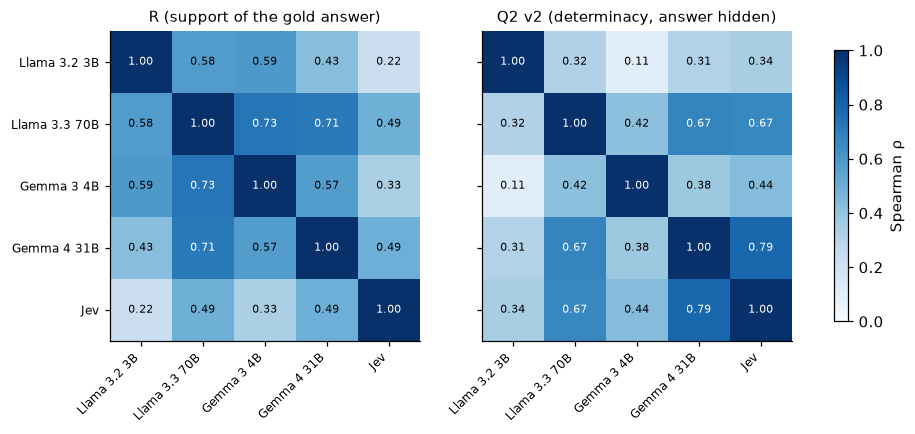

R: mean pairwise ρ between judges 0.514 (range 0.219–0.729)
Q2_v2: mean pairwise ρ between judges 0.443 (range 0.109–0.785)


In [13]:
def agreement(col):
    m = pd.DataFrame({LABEL[j]: wide[j].loc[orig_ids, col] for j in JUDGES})
    return m.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (col, title) in zip(axes, [("R", "R (support of the gold answer)"), ("Q2_v2", "Q2 v2 (determinacy, answer hidden)")]):
    c = agreement(col)
    im = ax.imshow(c.to_numpy(), vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(len(c)), c.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(c)), c.index if ax is axes[0] else [], fontsize=8)
    for a in range(len(c)):
        for b in range(len(c)):
            ax.text(b, a, f"{c.iloc[a, b]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if c.iloc[a, b] > 0.6 else "black")
    ax.set_title(title, fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label="Spearman ρ")
fig.savefig(FIG_DIR / "judges_agreement.pdf", bbox_inches="tight")
plt.show()
for col in ("R", "Q2_v2"):
    c = agreement(col).to_numpy()
    off = c[np.triu_indices_from(c, 1)]
    print(f"{col}: mean pairwise ρ between judges {off.mean():.3f} (range {off.min():.3f}–{off.max():.3f})")

**Findings: agreement between judges.**
- **On R, judges agree moderately** (mean pairwise ρ 0.51): the two large open-weight judges agree with each other at 0.71 and with Jev at 0.49; Llama 3B agrees with Jev at only 0.22.
- **On determinacy (Q2 under v2), the capable judges converge:** Gemma 31B and Jev agree at 0.79, Llama 70B and Jev at 0.67, and the two large judges at 0.67, while the small judges agree with anyone at 0.11–0.44.
- **For the paper:** answer-free determinacy is a shared signal among capable judges, which supports treating it as a property of the item rather than an artefact of one judge. It also means the small judges should not be used to measure it.

## 9. Summary for the paper

In [14]:
summary = pd.DataFrame({LABEL[j]: {
    "family": FAMILY[j], "size": f"{SIZE_B[j]}B" if j in SIZE_B else "—",
    "precision": {"llama32_3b": "bf16", "gemma3_4b": "bf16", "llama33_70b": "fp8", "gemma4_31b": "fp8"}.get(j, "—"),
    "AUROC R": f"{AUC[(j, 'R')][0]:.3f}",
    "AUROC Q2 v0 / v1 / v2": " / ".join("—" if np.isnan(AUC[(j, f'Q2_{v}')][0]) else f"{AUC[(j, f'Q2_{v}')][0]:.2f}" for v in ("v0", "v1", "v2")),
    "L v0": f"{leak_index(j, 'v0')[0]:.2f}",
    "ρ(Q1, Q2) v0 → v2": f"{float(SEP.loc[LABEL[j], 'ρ(Q1, Q2) v0'].split()[0]):.2f} → {float(SEP.loc[LABEL[j], 'ρ(Q1, Q2) v2'].split()[0]):.2f}",
    "ρ(R, I) v0 → v2": f"{float(SEP.loc[LABEL[j], 'ρ(R, I) v0'].split()[0]):.2f} → {float(SEP.loc[LABEL[j], 'ρ(R, I) v2'].split()[0]):.2f}",
} for j in JUDGES}).T
display(summary)

,family,size,precision,AUROC R,AUROC Q2 v0 / v1 / v2,L v0,"ρ(Q1, Q2) v0 → v2","ρ(R, I) v0 → v2"
Llama 3.2 3B,Llama,3B,bf16,0.689,0.61 / 0.58 / 0.50,0.61,0.70 → 0.47,0.50 → 0.38
Llama 3.3 70B,Llama,70B,fp8,0.880,0.86 / 0.84 / 0.50,0.94,0.83 → 0.50,0.73 → 0.52
Gemma 3 4B,Gemma,4B,bf16,0.706,0.66 / 0.67 / 0.50,0.77,0.85 → 0.61,0.76 → 0.58
Gemma 4 31B,Gemma,31B,fp8,0.894,0.89 / 0.83 / 0.50,0.99,0.84 → 0.54,0.72 → 0.44
Jev,Jev,—,—,0.942,0.92 / — / 0.50,0.95,0.83 → 0.49,0.67 → 0.44


In [15]:
def a(j, c):
    return AUC[(j, c)][0]

def rv(j, k):
    return float(SEP.loc[LABEL[j], k].split()[0])

lv0 = {j: leak_index(j, "v0")[0] for j in JUDGES}
print(f"""
METHODS — judge comparison. To test whether answer leakage is specific to Jev, we asked four open-weight
instruction-tuned judges the same battery, verbatim, on the {len(pairs)} original/negative pairs: Llama 3.2 3B and
Llama 3.3 70B, Gemma 3 4B and Gemma 4 31B. Each question was sent in its own request (Q1 and Q3, and Q2 in its v0
and v1 wordings, with the stated answer; Q2 in its v2 wording without it), and P(yes) was read from the
log-probabilities of the first generated token (temperature 0; yes/no token variants summed and renormalised).
All four judges were served by one provider via OpenRouter, the small judges in bf16 and the large judges in fp8, so
within each family size is confounded with precision; we therefore compare judges only by AUROC and rank
correlation. Intervals are pair-clustered bootstrap (AUROC) or Fisher-z (Spearman).

RESULTS — judge comparison. Every judge separates verified from wrong answers with its support question, more
strongly the larger the judge (AUROC of R: Llama {a('llama32_3b','R'):.2f} → {a('llama33_70b','R'):.2f}, Gemma
{a('gemma3_4b','R'):.2f} → {a('gemma4_31b','R'):.2f}; Jev {a('jev','R'):.2f}). When the determinacy question can see the
stated answer (v0), it separates wrong answers too (AUROC {min(a(j,'Q2_v0') for j in JUDGES):.2f}–{max(a(j,'Q2_v0') for j in JUDGES):.2f}),
reproducing {min(lv0.values()):.0%}–{max(lv0.values()):.0%} of each judge's own correctness signal; the share is
higher for the large judges (Llama {lv0['llama32_3b']:.2f} → {lv0['llama33_70b']:.2f}, Gemma {lv0['gemma3_4b']:.2f} → {lv0['gemma4_31b']:.2f}).
Asking the judge to assume the answer is correct (v1) changes this little (AUROC of Q2 under v1:
{min(a(j,'Q2_v1') for j in JUDGES[:-1]):.2f}–{max(a(j,'Q2_v1') for j in JUDGES[:-1]):.2f}). Asking it without the stated
answer (v2) removes the leakage by construction and lowers ρ(Q1, Q2) from {min(rv(j,'ρ(Q1, Q2) v0') for j in JUDGES):.2f}–{max(rv(j,'ρ(Q1, Q2) v0') for j in JUDGES):.2f}
to {min(rv(j,'ρ(Q1, Q2) v2') for j in JUDGES):.2f}–{max(rv(j,'ρ(Q1, Q2) v2') for j in JUDGES):.2f} for every judge.
""")


METHODS — judge comparison. To test whether answer leakage is specific to Jev, we asked four open-weight
instruction-tuned judges the same battery, verbatim, on the 995 original/negative pairs: Llama 3.2 3B and
Llama 3.3 70B, Gemma 3 4B and Gemma 4 31B. Each question was sent in its own request (Q1 and Q3, and Q2 in its v0
and v1 wordings, with the stated answer; Q2 in its v2 wording without it), and P(yes) was read from the
log-probabilities of the first generated token (temperature 0; yes/no token variants summed and renormalised).
All four judges were served by one provider via OpenRouter, the small judges in bf16 and the large judges in fp8, so
within each family size is confounded with precision; we therefore compare judges only by AUROC and rank
correlation. Intervals are pair-clustered bootstrap (AUROC) or Fisher-z (Spearman).

RESULTS — judge comparison. Every judge separates verified from wrong answers with its support question, more
strongly the larger the judge (AUROC of R:

**Summary.**
1. **R is valid for every judge, but its strength scales with the judge.** Small judges barely check arithmetic (AUROC 0.52–0.55).
2. **Answer leakage is general.** Every judge's determinacy question detects wrong answers when it sees them (v0), and the large judges reproduce 94–99% of their own correctness signal, like Jev (96%).
3. **Rewording does not fix it; hiding the answer does,** for every judge.
4. **The residual R–Q2 coupling under v2 (0.47–0.61) is shared by all judges,** consistent with covariance between items.
5. **Capable judges agree on answer-free determinacy** (ρ 0.67–0.79 with Jev), supporting it as an item property.

**Caveats** are in section 10; the main one is that size is confounded with fp8 serving (and, for Gemma, generation). Numbers here are the analysis of record for the judge comparison and supersede the informal values in the implementation plan's verification log.

## 10. Limitations

1. **Size is confounded with precision** in both families (small in bf16, large in fp8), and, for Gemma, with model generation. The two large judges also differ in size (70B vs 31B). Statements about size are therefore statements about "the larger, fp8-served judge of the family".
2. **One provider, one run per judge.** All four judges were served by Parasail through OpenRouter; each was scored once, with a 200-item repeat check (section 2). Serving changes at the provider are not under our control; every response is archived (DVC).
3. **Constructed negatives only.** As for Jev, R is validated against perturbed copies of verified answers, not natural label errors.
4. **Q3 checks are not yet human-validated**, which affects Q3 and I for every judge alike.
5. **Jev's v1 is missing on these pairs**: v1 was tested only on the 200-item pilot (notebook 02) and rejected, so the v1 comparison covers the four open-weight judges.
6. **Llama paraphrases were not run**, so paraphrase robustness covers the Gemma pair and Jev.
7. **Exploratory.** The judge comparison is not among Protocol v1's pre-registered hypotheses, and no gate reads it. The design (questions, items, scoring, determinism check) was fixed in code and tests before any real judge score existed.